# Machine Learning Lab: K-Means Clustering
## Seeds Dataset

**Experiment:** Determine a suitable number of clusters using the Elbow Method (WCSS) and the Silhouette Score.

### Aim
Apply K-Means to the supplied Seeds dataset, compare candidate cluster counts, and interpret the groups produced by the algorithm.

### Objectives
1. Load and inspect the supplied dataset.
2. Separate the seven numerical measurements from the variety label.
3. Standardize the measurements before calculating distances.
4. Plot WCSS across several values of *k* and inspect the Elbow curve.
5. Calculate silhouette scores for candidate cluster counts.
6. Fit and visualize a final K-Means model, then assess its alignment with the known varieties as a separate check.

### Method note
K-Means is an unsupervised algorithm. The `variety` column is therefore kept out of the model inputs. It is consulted only after clustering to compare the discovered groups with the known wheat varieties.

## 1. Libraries and reproducibility

The first cell imports the tools needed for data handling, scaling, clustering, evaluation, and plotting. A fixed random seed and multiple centroid initializations make the K-Means results reproducible and reduce the chance of a poor starting configuration.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
plt.rcParams.update({"figure.figsize": (8, 4.8), "font.size": 10})

## 2. Load the Seeds dataset

The supplied text file contains 210 observations. Each row has seven measurements followed by a variety code. The file has no header row, so descriptive column names are assigned after loading it as whitespace-delimited data.

In [2]:
column_names = [
    "area", "perimeter", "compactness", "kernel_length",
    "kernel_width", "asymmetry_coefficient", "kernel_groove_length",
    "variety"
]

df = pd.read_csv("seeds_dataset.txt", sep=r"\s+", header=None, names=column_names)

print("Dataset shape:", df.shape)
print("\nFirst five records:")
print(df.head().to_string(index=False))
print("\nData types:")
print(df.dtypes.to_string())

Dataset shape: (210, 8)

First five records:
 area  perimeter  compactness  kernel_length  kernel_width  asymmetry_coefficient  kernel_groove_length  variety
15.26      14.84       0.8710          5.763         3.312                  2.221                 5.220        1
14.88      14.57       0.8811          5.554         3.333                  1.018                 4.956        1
14.29      14.09       0.9050          5.291         3.337                  2.699                 4.825        1
13.84      13.94       0.8955          5.324         3.379                  2.259                 4.805        1
16.14      14.99       0.9034          5.658         3.562                  1.355                 5.175        1

Data types:
area                     float64
perimeter                float64
compactness              float64
kernel_length            float64
kernel_width             float64
asymmetry_coefficient    float64
kernel_groove_length     float64
variety                    int64


## 3. Initial data inspection

This step checks missing values, exact duplicate rows, and the distribution of the known variety labels. The labels describe the three wheat varieties, but they will not be used during K-Means fitting or when selecting *k* with the two internal measures.

In [3]:
feature_names = column_names[:-1]
X = df[feature_names].copy()
y = df["variety"].astype(int).copy()

print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nVariety counts:")
print(y.value_counts().sort_index().to_string())
print("\nFeature summary:")
print(X.describe().round(3).to_string())

Missing values: 0
Duplicate rows: 0

Variety counts:
variety
1    70
2    70
3    70

Feature summary:
          area  perimeter  compactness  kernel_length  kernel_width  asymmetry_coefficient  kernel_groove_length
count  210.000    210.000      210.000        210.000       210.000                210.000               210.000
mean    14.848     14.559        0.871          5.629         3.259                  3.700                 5.408
std      2.910      1.306        0.024          0.443         0.378                  1.504                 0.491
min     10.590     12.410        0.808          4.899         2.630                  0.765                 4.519
25%     12.270     13.450        0.857          5.262         2.944                  2.562                 5.045
50%     14.355     14.320        0.873          5.524         3.237                  3.599                 5.223
75%     17.305     15.715        0.888          5.980         3.562                  4.769                

## 4. Prepare and standardize the measurements

K-Means assigns observations according to distances from cluster centroids. The seven measurements use different numerical ranges, so standardization is applied to give each feature a comparable scale. The variety label is deliberately excluded from this transformation.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaled_df = pd.DataFrame(X_scaled, columns=feature_names)
print("Standardized feature means (approximately zero):")
print(scaled_df.mean().round(3).to_string())
print("\nStandardized feature standard deviations (approximately one):")
print(scaled_df.std(ddof=0).round(3).to_string())

Standardized feature means (approximately zero):
area                    -0.0
perimeter                0.0
compactness              0.0
kernel_length           -0.0
kernel_width            -0.0
asymmetry_coefficient   -0.0
kernel_groove_length    -0.0

Standardized feature standard deviations (approximately one):
area                     1.0
perimeter                1.0
compactness              1.0
kernel_length            1.0
kernel_width             1.0
asymmetry_coefficient    1.0
kernel_groove_length     1.0


## 5. Elbow Method using WCSS

Within-Cluster Sum of Squares (WCSS), also called K-Means inertia, measures the total squared distance between each observation and its assigned centroid. It normally decreases as more clusters are added. The Elbow Method looks for a point after which the reduction becomes less pronounced.

In [5]:
k_values_wcss = range(1, 11)
wcss = []

for k in k_values_wcss:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

wcss_table = pd.DataFrame({"k": list(k_values_wcss), "WCSS": wcss})
print(wcss_table.to_string(index=False, formatters={"WCSS": "{:.2f}".format}))

 k    WCSS
 1 1470.00
 2  659.17
 3  430.66
 4  371.30
 5  326.31
 6  289.22
 7  262.32
 8  239.95
 9  222.85
10  204.32


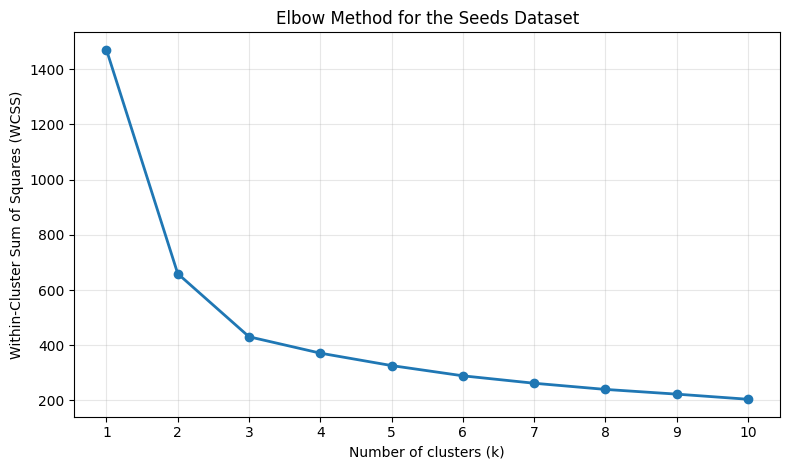

In [6]:
plt.figure(figsize=(8, 4.8))
plt.plot(list(k_values_wcss), wcss, marker="o", linewidth=2)
plt.title("Elbow Method for the Seeds Dataset")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.xticks(list(k_values_wcss))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Reading the Elbow curve

The curve drops sharply when moving from two to three clusters, then the reductions become more gradual. This makes **three clusters a reasonable elbow-based candidate**. The elbow is a visual guide rather than an exact mathematical test, so it is considered alongside the silhouette results.

## 6. Silhouette score comparison

The silhouette score evaluates how close each observation is to its own cluster compared with other clusters. It ranges from -1 to 1, with larger values generally indicating better separation and cohesion. Scores are calculated for *k* values from 2 to 8, since a silhouette score is not defined for a single cluster.

In [7]:
k_values_sil = range(2, 9)
silhouette_values = []
models_by_k = {}
labels_by_k = {}

for k in k_values_sil:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    models_by_k[k] = model
    labels_by_k[k] = labels
    silhouette_values.append(score)

silhouette_table = pd.DataFrame({
    "k": list(k_values_sil),
    "silhouette_score": silhouette_values
})
print(silhouette_table.to_string(index=False, formatters={"silhouette_score": "{:.4f}".format}))
best_k_silhouette = int(silhouette_table.loc[silhouette_table["silhouette_score"].idxmax(), "k"])
print("\nHighest silhouette score occurs at k =", best_k_silhouette)

 k silhouette_score
 2           0.4658
 3           0.4007
 4           0.3276
 5           0.2864
 6           0.2913
 7           0.2812
 8           0.2619

Highest silhouette score occurs at k = 2


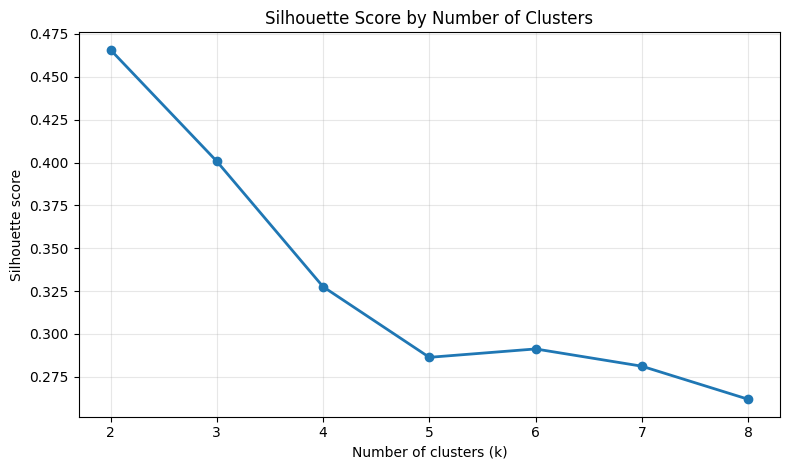

In [8]:
plt.figure(figsize=(8, 4.8))
plt.plot(silhouette_table["k"], silhouette_table["silhouette_score"], marker="o", linewidth=2)
plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.xticks(list(k_values_sil))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Comparing the two selection measures

For this dataset, the highest tested silhouette score occurs at **k = 2**, while the WCSS curve has a visible bend around **k = 3**. The measures do not identify exactly the same value. This is a useful result rather than an error: WCSS measures compactness, whereas silhouette score balances within-cluster cohesion against separation from other clusters.

For the primary model in this report, **k = 2 is selected by the explicit silhouette maximum**. The three-cluster solution is also retained for a separate post-clustering comparison because the dataset contains three known varieties. The labels are not used to fit either solution.

## 7. Fit the selected K-Means model

The model below uses the value selected by the highest silhouette score. Cluster numbers are arbitrary identifiers and should not be interpreted as an ordering or category name.

In [9]:
selected_k = best_k_silhouette
final_kmeans = KMeans(n_clusters=selected_k, random_state=RANDOM_STATE, n_init=20)
final_labels = final_kmeans.fit_predict(X_scaled)

cluster_counts = pd.Series(final_labels, name="cluster").value_counts().sort_index()
print("Selected number of clusters:", selected_k)
print("\nObservations in each cluster:")
print(cluster_counts.to_string())
print("\nFinal model silhouette score:", round(silhouette_score(X_scaled, final_labels), 4))

Selected number of clusters: 2

Observations in each cluster:
cluster
0     77
1    133

Final model silhouette score: 0.4658


## 8. Examine cluster profiles

Cluster profiles show the average values of the original measurements within each group. These summaries help describe how the clusters differ in physical seed characteristics. Values are reported in the original units, not the standardized units used to fit K-Means.

In [10]:
profile_data = X.copy()
profile_data["cluster"] = final_labels
cluster_profiles = profile_data.groupby("cluster")[feature_names].mean().round(3)
print(cluster_profiles.to_string())

           area  perimeter  compactness  kernel_length  kernel_width  asymmetry_coefficient  kernel_groove_length
cluster                                                                                                          
0        18.159     16.055        0.884          6.127         3.661                  3.480                 5.972
1        12.931     13.693        0.864          5.340         3.026                  3.827                 5.082


## 9. Visualize the clusters with PCA

The model uses all seven standardized measurements. Principal Component Analysis (PCA) is used only to project those measurements into two dimensions for plotting. The two plotted components summarize as much variation as possible in a two-dimensional view, but they do not replace the original seven-dimensional clustering.

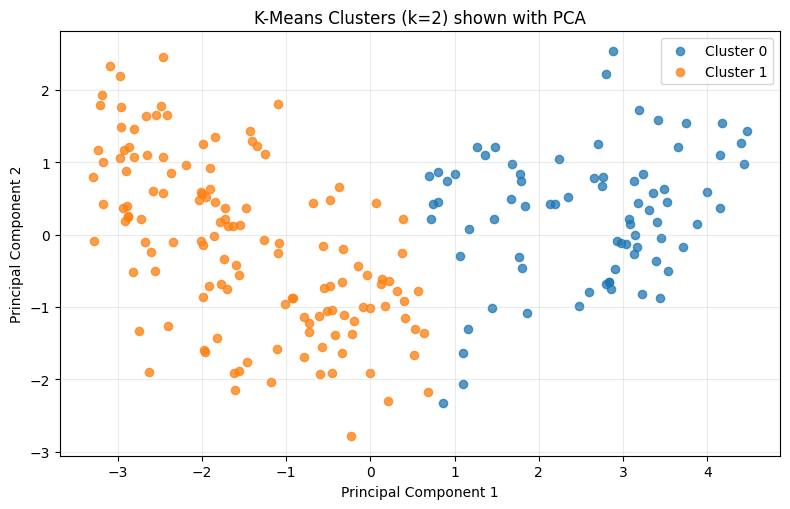

Variance represented by the first two components: 0.8898


In [11]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
explained = pca.explained_variance_ratio_.sum()

plt.figure(figsize=(8, 5.2))
for cluster_id in sorted(np.unique(final_labels)):
    mask = final_labels == cluster_id
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f"Cluster {cluster_id}", alpha=0.75, s=35)
plt.title(f"K-Means Clusters (k={selected_k}) shown with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()
print("Variance represented by the first two components:", round(explained, 4))

## 10. Compare clusters with the known varieties

The variety labels are now brought back for an external check. The cross-tabulation shows how the original classes are distributed across the two clusters. The Adjusted Rand Index (ARI) measures agreement between the clustering and known labels, adjusted for chance. It is not used to train the model or select *k*.

In [12]:
comparison = pd.crosstab(
    pd.Series(y, name="Known variety"),
    pd.Series(final_labels, name="K-Means cluster")
)
print("Known variety by selected cluster:")
print(comparison.to_string())
print("\nAdjusted Rand Index for selected k:", round(adjusted_rand_score(y, final_labels), 4))

# Also inspect the elbow-based candidate k=3 as a post-hoc comparison.
k3_labels = labels_by_k[3]
print("Adjusted Rand Index for k=3 candidate:", round(adjusted_rand_score(y, k3_labels), 4))
print("k=3 cluster sizes:")
print(pd.Series(k3_labels).value_counts().sort_index().to_string())

Known variety by selected cluster:
K-Means cluster   0   1
Known variety          
1                 9  61
2                68   2
3                 0  70

Adjusted Rand Index for selected k: 0.4805
Adjusted Rand Index for k=3 candidate: 0.7733
k=3 cluster sizes:
0    72
1    67
2    71


## 11. Findings and interpretation

- The supplied file contains 210 observations, seven numerical measurements, and three equally represented variety labels.
- Standardization was applied because K-Means relies on distances and the features have different units and ranges.
- WCSS decreases as *k* increases. The curve has a visible bend around three clusters, suggesting *k = 3* as an elbow candidate.
- Among the tested values, the silhouette score is highest at *k = 2*. This report therefore uses two clusters as its primary silhouette-selected solution.
- The elbow and silhouette methods do not fully agree. The choice should be presented with this limitation instead of claiming that both methods identify the same optimum.
- The known variety labels are used only after clustering. The external ARI comparison can show whether the three-cluster alternative aligns more closely with the known varieties, but this does not turn K-Means into a supervised model.

### Learning outcomes
After completing the experiment, the learner should be able to load a tabular dataset, standardize numerical features, calculate WCSS, interpret an Elbow curve, compare silhouette scores, fit K-Means, and interpret clusters using profile summaries and a PCA visualization.

### Conclusion
K-Means clustering was applied to the supplied Seeds dataset using seven standardized seed measurements. The silhouette score selected two clusters among the tested values, while the Elbow curve suggested a possible bend at three clusters. Since the two internal measures differ, the report records both findings and uses the silhouette maximum for its primary model. A post-clustering comparison with the known varieties provides additional context without influencing the unsupervised fit.